# Лабораторна робота: Customer Segmentation (K-means)

**Мета:** розбити клієнтів торгового центру на групи зі схожими характеристиками.
**Ключові поняття:** кластеризація, K-means, Elbow method, Silhouette score, PCA.
**Датасет:** Mall Customer Segmentation Data (200 клієнтів: `Gender`, `Age`, `Annual Income (k$)`, `Spending Score (1-100)`).

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples
from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 1. Попередня обробка даних

### 1.1 Завантаження даних

In [2]:
df = pd.read_csv("data/Mall_Customers.csv")
print(df.shape)
df.head()

(200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
df.info()
df.describe(include="all").T

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
CustomerID,200.0,NaN,NaN,NaN,100.5,57.879185,1.0,50.75,100.5,150.25,200.0
Gender,200,2,Female,112,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,200.0,NaN,NaN,NaN,38.85,13.969007,18.0,28.75,36.0,49.0,70.0
Annual Income (k$),200.0,NaN,NaN,NaN,60.56,26.264721,15.0,41.5,61.5,78.0,137.0
Spending Score (1-100),200.0,NaN,NaN,NaN,50.2,25.823522,1.0,34.75,50.0,73.0,99.0


### 1.2 Очищення: пропуски, дублікати, викиди

In [4]:
print("Пропуски:\n", df.isna().sum(), sep="")
print("Дублікати рядків:", df.duplicated().sum())
print("Дублікати CustomerID:", df["CustomerID"].duplicated().sum())

Пропуски:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64
Дублікати рядків: 0
Дублікати CustomerID: 0


In [5]:
# Викиди за правилом IQR (1.5 * IQR)
num_cols = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
rows = []
for c in num_cols:
    q1, q3 = df[c].quantile([.25, .75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n = ((df[c] < lo) | (df[c] > hi)).sum()
    rows.append((c, lo, hi, n))
pd.DataFrame(rows, columns=["ознака", "нижня межа", "верхня межа", "к-сть викидів"])

,ознака,нижня межа,верхня межа,к-сть викидів
0,Age,-1.625,79.375,0
1,Annual Income (k$),-13.250,132.750,2
2,Spending Score (1-100),-22.625,130.375,0


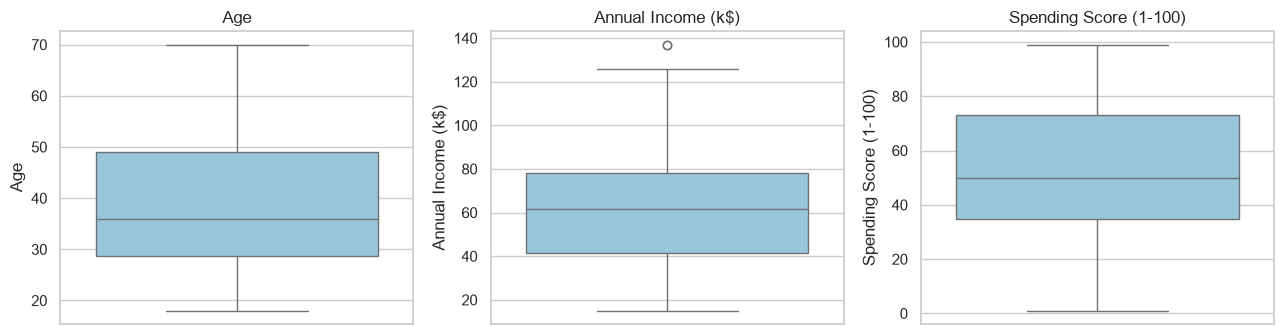

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
for a, c in zip(ax, num_cols):
    sns.boxplot(y=df[c], ax=a, color="#8ecae6")
    a.set_title(c)
plt.tight_layout(); plt.show()

Пропусків і дублікатів немає. За IQR є лише 2 помірні викиди у `Annual Income` (дуже високі доходи) –
це реальні клієнти з високим доходом (потенційно окремий сегмент), а не помилки вводу, тому **викиди не видаляємо**
(при 200 спостереженнях видалення лише зменшило б вибірку і приховало б цікавий сегмент).

### 1.3 Вибір ознак

Для кластеризації беремо **`Annual Income`** та **`Spending Score`** (основна пара для бізнес-інтерпретації)
і **`Age`**. `CustomerID` – ідентифікатор, інформації не несе. `Gender` – категоріальна, K-means з евклідовою
відстанню для неї підходить погано, тому використаємо її лише при інтерпретації кластерів (профілювання),
а не для побудови кластерів.

In [7]:
features = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
X = df[features].copy()

### 1.4 Нормалізація

K-means працює з відстанями, тому ознаки приводимо до однакового масштабу (StandardScaler: середнє 0, σ = 1).

In [8]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
pd.DataFrame(X_scaled, columns=features).describe().loc[["mean", "std"]].round(3)

,Age,Annual Income (k$),Spending Score (1-100)
mean,-0.000,-0.000,-0.000
std,1.003,1.003,1.003


## 2. Розвідувальний аналіз (EDA)

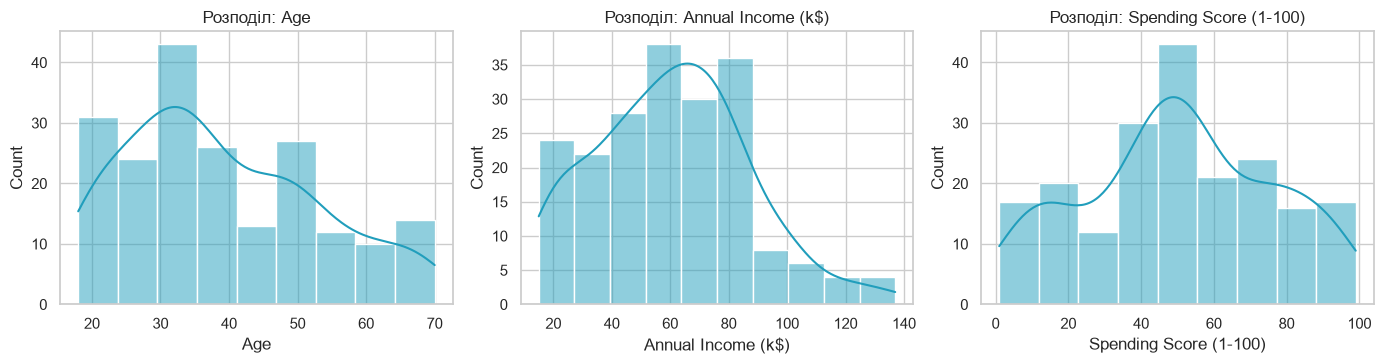

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for a, c in zip(ax, features):
    sns.histplot(df[c], kde=True, ax=a, color="#219ebc")
    a.set_title(f"Розподіл: {c}")
plt.tight_layout(); plt.show()

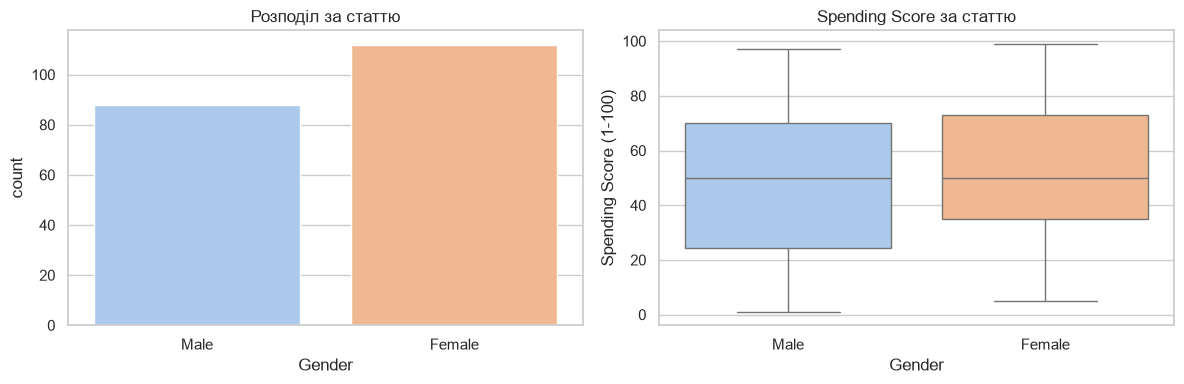

,Age,Annual Income (k$),Spending Score (1-100)
Gender,,,
Female,38.1,59.2,51.5
Male,39.8,62.2,48.5


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x="Gender", ax=ax[0], palette="pastel")
ax[0].set_title("Розподіл за статтю")
sns.boxplot(data=df, x="Gender", y="Spending Score (1-100)", ax=ax[1], palette="pastel")
ax[1].set_title("Spending Score за статтю")
plt.tight_layout(); plt.show()
df.groupby("Gender")[features].mean().round(1)

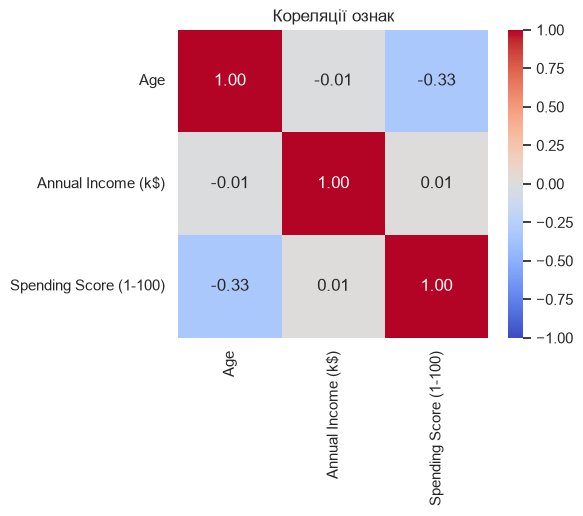

In [11]:
plt.figure(figsize=(5, 4))
sns.heatmap(df[features].corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
plt.title("Кореляції ознак"); plt.show()

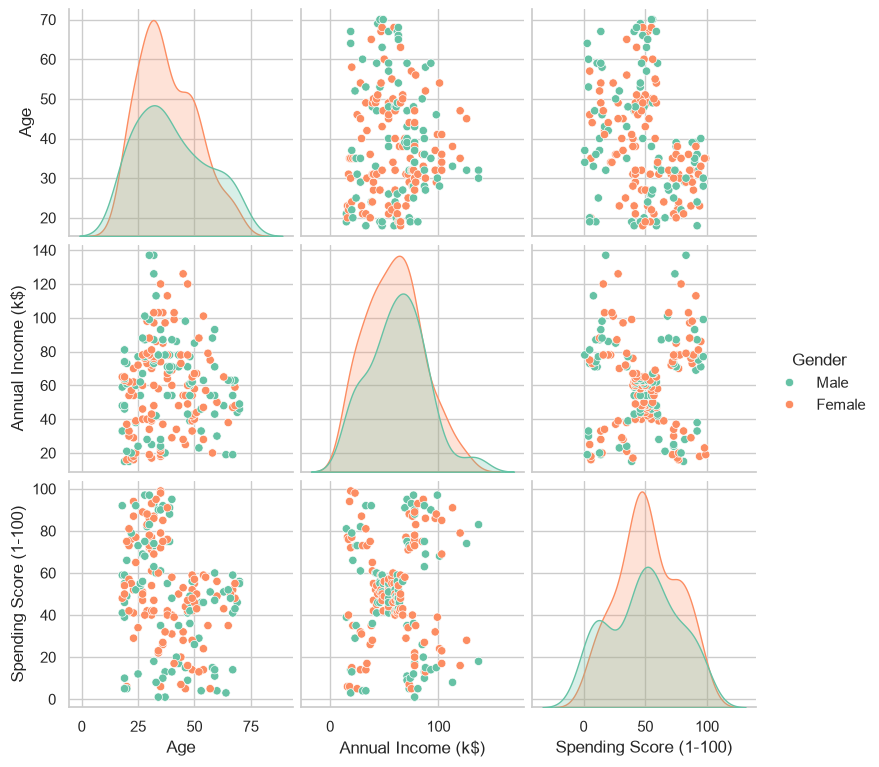

In [12]:
sns.pairplot(df, vars=features, hue="Gender", diag_kind="kde", height=2.6, palette="Set2")
plt.show()

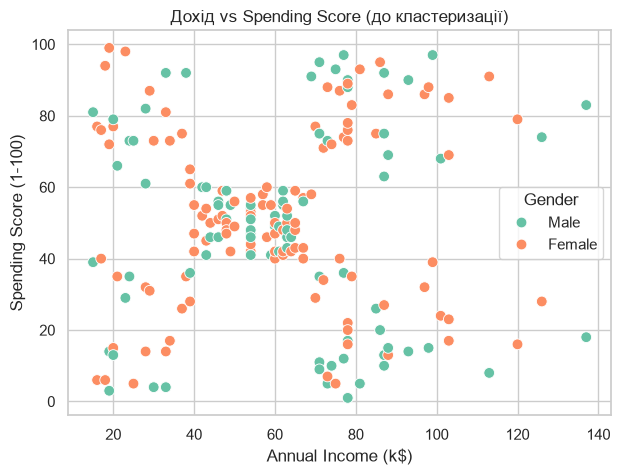

In [13]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="Annual Income (k$)", y="Spending Score (1-100)", hue="Gender", s=60, palette="Set2")
plt.title("Дохід vs Spending Score (до кластеризації)"); plt.show()

**Спостереження.** Кореляції між ознаками слабкі (найпомітніша – від’ємна між `Age` та `Spending Score`),
тобто ознаки несуть різну інформацію. На графіку «дохід – spending score» вже візуально видно кілька
компактних «хмар» – це добрий знак для K-means.

## 3. K-means кластеризація

### 3.1 Вибір числа кластерів k

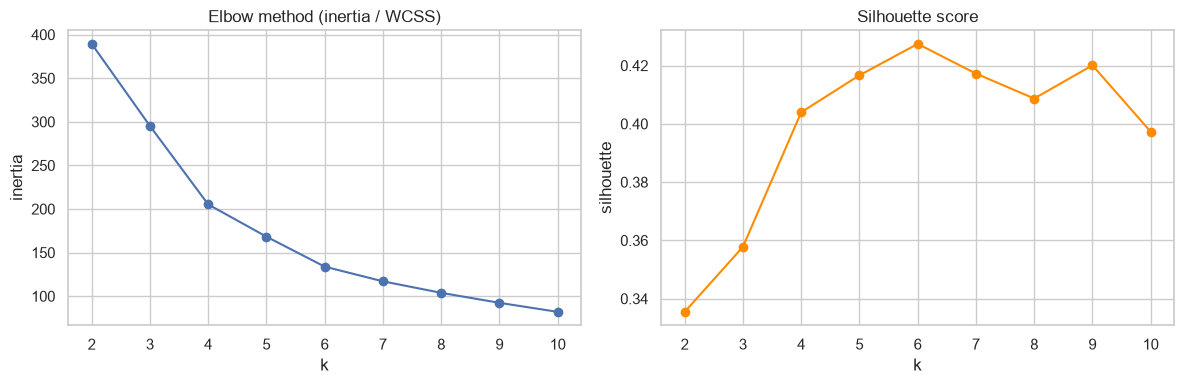

,k,inertia,silhouette
0,2,389.4,0.3355
1,3,295.2,0.3578
2,4,205.2,0.4040
3,5,168.2,0.4166
4,6,133.9,0.4274
5,7,117.0,0.4172
6,8,103.8,0.4087
7,9,92.3,0.4201
8,10,82.0,0.3973


In [14]:
ks = range(2, 11)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(X_scaled)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X_scaled, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(list(ks), inertia, "o-"); ax[0].set_title("Elbow method (inertia / WCSS)")
ax[0].set_xlabel("k"); ax[0].set_ylabel("inertia")
ax[1].plot(list(ks), sil, "o-", color="darkorange"); ax[1].set_title("Silhouette score")
ax[1].set_xlabel("k"); ax[1].set_ylabel("silhouette")
plt.tight_layout(); plt.show()
pd.DataFrame({"k": list(ks), "inertia": np.round(inertia, 1), "silhouette": np.round(sil, 4)})

In [15]:
best_k_sil = list(ks)[int(np.argmax(sil))]
print("k з максимальним silhouette:", best_k_sil)

k з максимальним silhouette: 6


Метод ліктя показує, що спад inertia сповільнюється приблизно після k = 5–6. Silhouette максимальний при k = 6 (≈ 0.427),
проте різниця з k = 5 (≈ 0.417) і k = 7 (≈ 0.417) невелика. Тому для кандидатів 4, 5, 6 нижче порівнюємо silhouette-діаграми;
k = 6 обираємо як максимум silhouette, який також дає інтерпретовні бізнес-сегменти.

### 3.2 Silhouette-діаграми для кандидатів

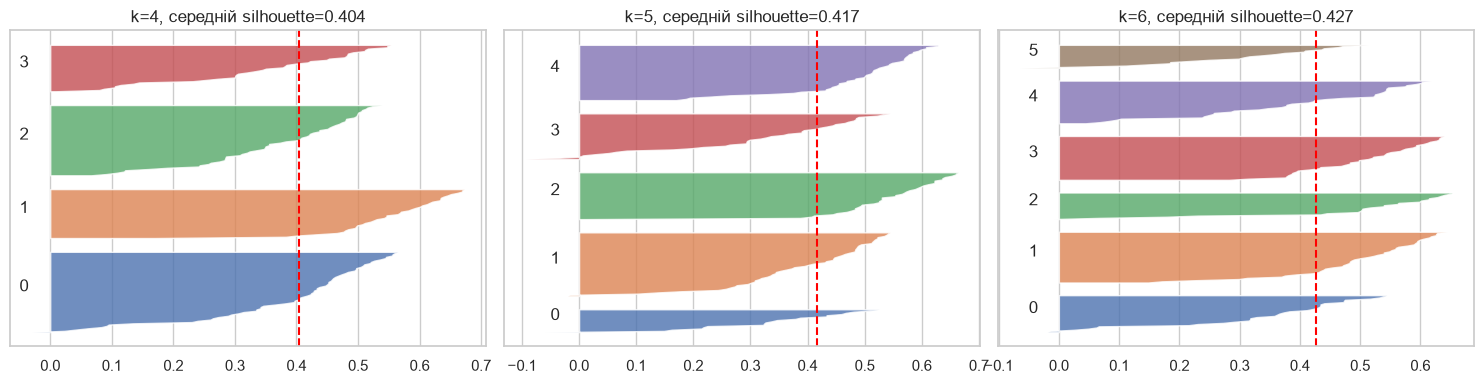

In [16]:
cands = [4, 5, 6]
fig, ax = plt.subplots(1, len(cands), figsize=(15, 4))
for a, k in zip(ax, cands):
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(X_scaled)
    s_vals = silhouette_samples(X_scaled, km.labels_)
    y = 10
    for i in range(k):
        v = np.sort(s_vals[km.labels_ == i])
        a.fill_betweenx(np.arange(y, y + len(v)), 0, v, alpha=.8)
        a.text(-0.05, y + len(v) / 2, str(i))
        y += len(v) + 10
    a.axvline(s_vals.mean(), color="red", ls="--")
    a.set_title(f"k={k}, середній silhouette={s_vals.mean():.3f}")
    a.set_yticks([])
plt.tight_layout(); plt.show()

### 3.3 Фінальна модель

In [17]:
K = best_k_sil
kmeans = KMeans(n_clusters=K, n_init=50, random_state=RANDOM_STATE).fit(X_scaled)
df["Cluster"] = kmeans.labels_
print("Обрано k =", K)
df["Cluster"].value_counts().sort_index()

Обрано k = 6


Cluster
0    33
1    45
2    24
3    39
4    38
5    21
Name: count, dtype: int64

### 3.4 Аналіз кластерів

In [18]:
profile = df.groupby("Cluster").agg(
    size=("CustomerID", "count"),
    age=("Age", "mean"),
    income=("Annual Income (k$)", "mean"),
    spending=("Spending Score (1-100)", "mean"),
    female_share=("Gender", lambda s: (s == "Female").mean()),
).round(2)
profile["share_%"] = (profile["size"] / len(df) * 100).round(1)
profile

,size,age,income,spending,female_share,share_%
Cluster,,,,,,
0,33,41.94,88.94,16.97,0.42,16.5
1,45,56.33,54.27,49.07,0.58,22.5
2,24,25.25,25.83,76.92,0.58,12.0
3,39,32.69,86.54,82.13,0.54,19.5
4,38,26.68,57.58,47.79,0.63,19.0
5,21,45.52,26.29,19.38,0.62,10.5


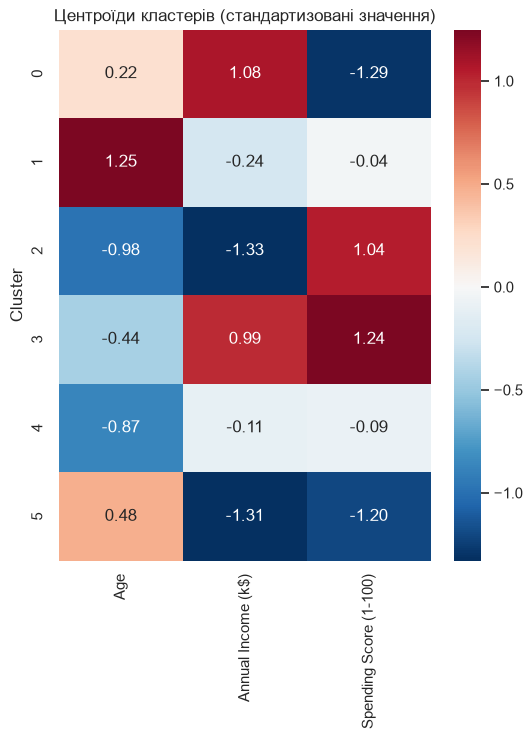

In [19]:
prof_z = pd.DataFrame(kmeans.cluster_centers_, columns=features).round(2)
prof_z.index.name = "Cluster"
plt.figure(figsize=(6, 0.9 * K + 1.5))
sns.heatmap(prof_z, annot=True, cmap="RdBu_r", center=0, fmt=".2f")
plt.title("Центроїди кластерів (стандартизовані значення)"); plt.show()

## 4. Оцінка якості кластерів

In [20]:
from sklearn.metrics import davies_bouldin_score, calinski_harabasz_score
print(f"Silhouette Score        : {silhouette_score(X_scaled, df['Cluster']):.4f}  (ближче до 1 – краще)")
print(f"Davies-Bouldin index    : {davies_bouldin_score(X_scaled, df['Cluster']):.4f}  (менше – краще)")
print(f"Calinski-Harabasz index : {calinski_harabasz_score(X_scaled, df['Cluster']):.1f}  (більше – краще)")

Silhouette Score        : 0.4274  (ближче до 1 – краще)
Davies-Bouldin index    : 0.8277  (менше – краще)
Calinski-Harabasz index : 135.1  (більше – краще)


In [21]:
# Стабільність: ARI між запусками з різними random_state
from sklearn.metrics import adjusted_rand_score
base = df["Cluster"].values
aris = [adjusted_rand_score(base, KMeans(n_clusters=K, n_init=10, random_state=s).fit(X_scaled).labels_)
        for s in range(1, 11)]
print("Середній ARI між запусками:", round(float(np.mean(aris)), 3))

Середній ARI між запусками: 0.99


## 5. Візуалізація

### 5.1 PCA

Пояснена дисперсія PC1, PC2: [0.443 0.333] | разом: 0.776


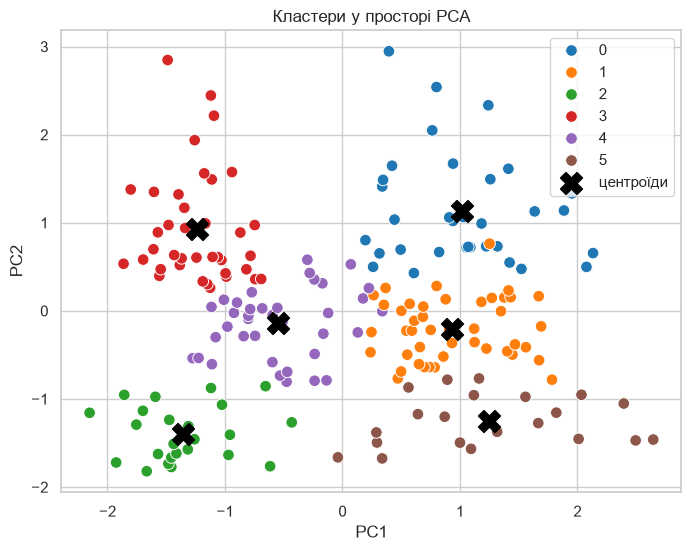

In [22]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
Z = pca.fit_transform(X_scaled)
print("Пояснена дисперсія PC1, PC2:", pca.explained_variance_ratio_.round(3),
      "| разом:", pca.explained_variance_ratio_.sum().round(3))
centers_pca = pca.transform(kmeans.cluster_centers_)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=df["Cluster"], palette="tab10", s=70)
plt.scatter(centers_pca[:, 0], centers_pca[:, 1], c="black", marker="X", s=250, label="центроїди")
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title("Кластери у просторі PCA"); plt.legend(); plt.show()

In [23]:
pd.DataFrame(pca.components_, columns=features, index=["PC1", "PC2"]).round(2)

,Age,Annual Income (k$),Spending Score (1-100)
PC1,0.71,-0.05,-0.71
PC2,0.03,1.00,-0.04


### 5.2 Кластери в початкових ознаках

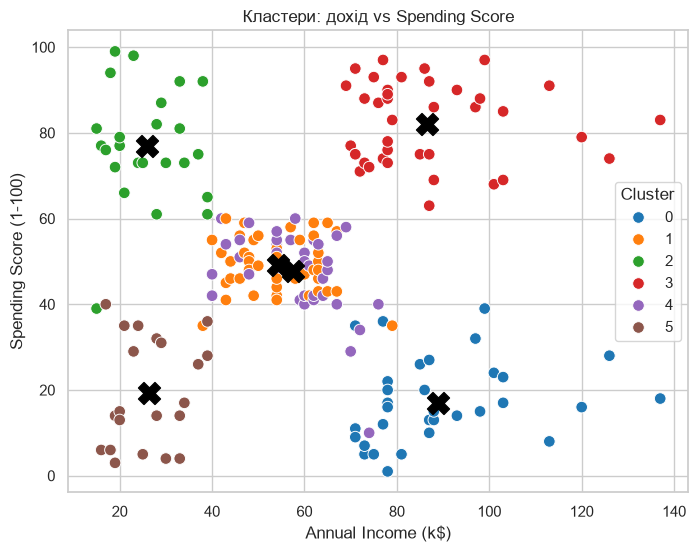

In [24]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x="Annual Income (k$)", y="Spending Score (1-100)", hue="Cluster", palette="tab10", s=70)
cc = scaler.inverse_transform(kmeans.cluster_centers_)
plt.scatter(cc[:, 1], cc[:, 2], c="black", marker="X", s=250)
plt.title("Кластери: дохід vs Spending Score"); plt.show()

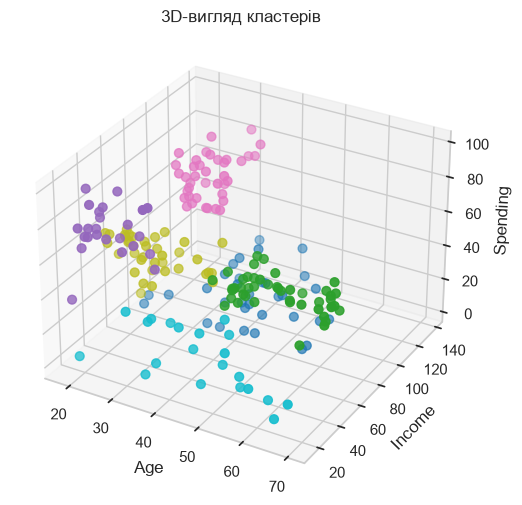

In [25]:
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
sc = ax.scatter(df["Age"], df["Annual Income (k$)"], df["Spending Score (1-100)"], c=df["Cluster"], cmap="tab10", s=40)
ax.set_xlabel("Age"); ax.set_ylabel("Income"); ax.set_zlabel("Spending")
ax.set_title("3D-вигляд кластерів"); plt.show()

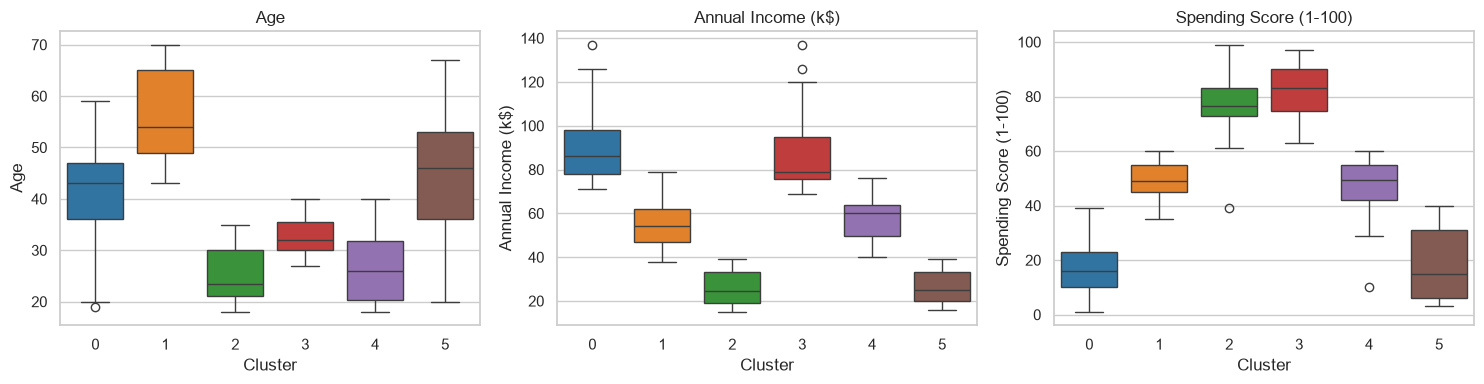

In [26]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, c in zip(ax, features):
    sns.boxplot(data=df, x="Cluster", y=c, ax=a, palette="tab10")
    a.set_title(c)
plt.tight_layout(); plt.show()

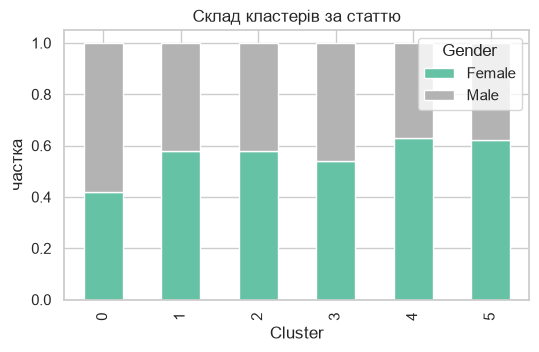

In [27]:
ct = pd.crosstab(df["Cluster"], df["Gender"], normalize="index").round(2)
ct.plot(kind="bar", stacked=True, figsize=(6, 3.5), colormap="Set2")
plt.title("Склад кластерів за статтю"); plt.ylabel("частка"); plt.show()

## 6. Інтерпретація кластерів

In [28]:
def label_cluster(r):
    inc = "високий" if r["income"] >= 70 else ("середній" if r["income"] >= 40 else "низький")
    spd = "високі" if r["spending"] >= 60 else ("середні" if r["spending"] >= 40 else "низькі")
    age = "молоді" if r["age"] < 35 else ("середнього віку" if r["age"] < 50 else "старші")
    return f"{age}, дохід {inc}, витрати {spd}"

summary = profile.copy()
summary["опис"] = summary.apply(label_cluster, axis=1)
summary[["size", "share_%", "age", "income", "spending", "опис"]]

,size,share_%,age,income,spending,опис
Cluster,,,,,,
0,33,16.5,41.94,88.94,16.97,"середнього віку, дохід високий, витрати низькі"
1,45,22.5,56.33,54.27,49.07,"старші, дохід середній, витрати середні"
2,24,12.0,25.25,25.83,76.92,"молоді, дохід низький, витрати високі"
3,39,19.5,32.69,86.54,82.13,"молоді, дохід високий, витрати високі"
4,38,19.0,26.68,57.58,47.79,"молоді, дохід середній, витрати середні"
5,21,10.5,45.52,26.29,19.38,"середнього віку, дохід низький, витрати низькі"


### Бізнес-висновки

Отримано k = 6 кластерів (silhouette ≈ 0.43, стабільність між запусками ARI ≈ 0.99):

| Кластер | К-сть | Вік | Дохід, k$ | Spending | Сегмент | Рекомендація |
|---|---|---|---|---|---|---|
| 3 | 39 | ~33 | ~87 | ~82 | **VIP**: молоді, високий дохід, високі витрати | програма лояльності, ексклюзивні пропозиції, нові колекції |
| 0 | 33 | ~42 | ~89 | ~17 | **Заощадливі багаті**: високий дохід, низькі витрати | потенціал зростання: преміум-пропозиції, персональний маркетинг |
| 2 | 24 | ~25 | ~26 | ~77 | **Імпульсивна молодь**: низький дохід, високі витрати | знижки, розстрочка, акції |
| 4 | 38 | ~27 | ~58 | ~48 | **Молоді середнього рівня** | стандартні акції, утримання, стимулювання росту чека |
| 1 | 45 | ~56 | ~54 | ~49 | **Старші середнього рівня** (найбільший сегмент) | сервіс, зручність, сезонні пропозиції |
| 5 | 21 | ~46 | ~26 | ~19 | **Економні**: низький дохід, низькі витрати | розпродажі; низький пріоритет маркетингу |

Ключові висновки: Spending Score майже не залежить від доходу в цілому, а розрізняє клієнтів у парі «дохід × вік».
Найбільша різниця в поведінці – між двома групами з однаково високим доходом (кластери 3 і 0): віком і готовністю витрачати.

### Обмеження
- Вибірка невелика (200 клієнтів), датасет синтетичний/навчальний.
- K-means припускає кулясті кластери однакового розміру та чутливий до масштабу й викидів.
- `Gender` не використовувалась у кластеризації; для змішаних даних можна застосувати K-prototypes або Gower + ієрархічну кластеризацію.
- Спробуйте також порівняти з Agglomerative / DBSCAN / GMM.

## 7. Додатково: порівняння з іншими алгоритмами (опційно)

In [29]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score

agg = AgglomerativeClustering(n_clusters=K).fit_predict(X_scaled)
gmm = GaussianMixture(n_components=K, random_state=RANDOM_STATE, n_init=5).fit_predict(X_scaled)

pd.DataFrame({
    "алгоритм": ["K-means", "Agglomerative (Ward)", "GMM"],
    "silhouette": [silhouette_score(X_scaled, df["Cluster"]),
                   silhouette_score(X_scaled, agg),
                   silhouette_score(X_scaled, gmm)],
    "ARI відносно K-means": [1.0, adjusted_rand_score(df["Cluster"], agg), adjusted_rand_score(df["Cluster"], gmm)],
}).round(3)

,алгоритм,silhouette,ARI відносно K-means
0,K-means,0.427,1.000
1,Agglomerative (Ward),0.420,0.881
2,GMM,0.377,0.696
